# Credit Risk Scoring - German Credit data
Steps: 1) cleaning + EDA, 2) split + features, 3) models, 4) SHAP, 5) causality.

## 1. Data cleaning & EDA

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, shap, warnings
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")
RS = 42

# column names come from german.doc (attributes 1..20) + target
cols = ["checking_status", "duration", "credit_history", "purpose", "credit_amount",
        "savings", "employment", "installment_rate", "personal_status", "other_debtors",
        "residence_since", "property", "age", "other_installments", "housing",
        "existing_credits", "job", "num_dependents", "telephone", "foreign_worker", "target"]
df = pd.read_csv("statlog+german+credit+data/german.data", sep=" ", header=None, names=cols)
# raw target: 1 = good, 2 = bad  ->  0 = good, 1 = bad
df["target"] = (df["target"] == 2).astype(int)
df.head()

/home/tomcat/Downloads/mc/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installments,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


In [2]:
num_cols = df.drop(columns="target").select_dtypes("number").columns.tolist()
cat_cols = df.drop(columns="target").select_dtypes("object").columns.tolist()
print("rows, columns:", df.shape)
print("numerical (%d):" % len(num_cols), num_cols)
print("categorical (%d):" % len(cat_cols), cat_cols)
print("missing values:", df.isna().sum().sum())
vc = df["target"].value_counts()
print("good:", vc[0], " bad:", vc[1], " imbalance ratio good:bad = %.2f : 1" % (vc[0] / vc[1]))

rows, columns: (1000, 21)
numerical (7): ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
categorical (13): ['checking_status', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status', 'other_debtors', 'property', 'other_installments', 'housing', 'job', 'telephone', 'foreign_worker']
missing values: 0
good: 700  bad: 300  imbalance ratio good:bad = 2.33 : 1


**Report:** 1000 samples, 20 features (7 numerical, 13 categorical), no missing values. Classes: 700 good vs 300 bad (ratio 2.33:1, moderately imbalanced). In this dataset 'unknown' is a real category (e.g. savings A65), not a NaN.

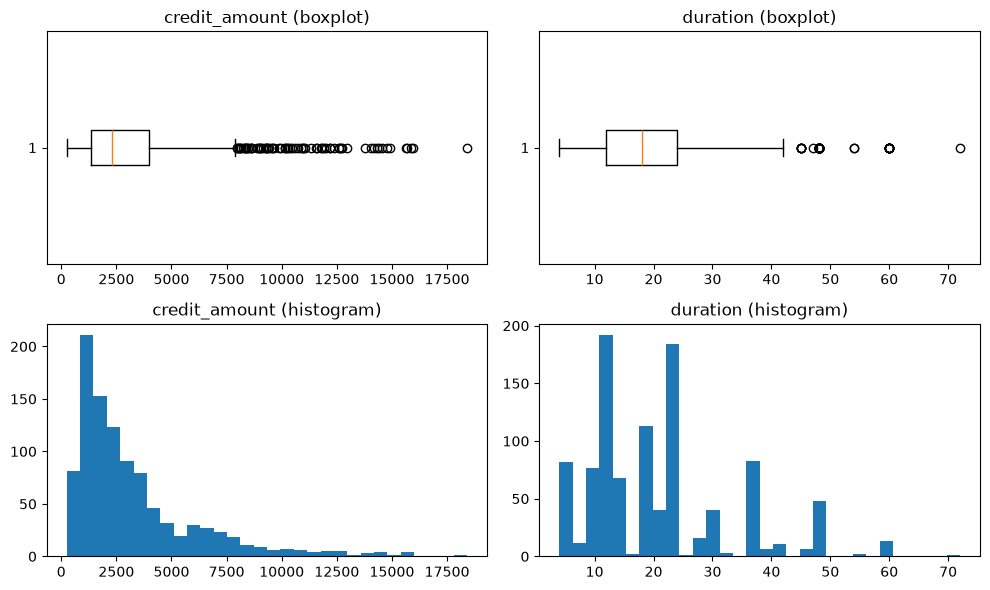

credit_amount outliers (IQR rule): 72


In [3]:
# outliers: key numeric features
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for i, c in enumerate(["credit_amount", "duration"]):
    ax[0, i].boxplot(df[c], vert=False); ax[0, i].set_title(c + " (boxplot)")
    ax[1, i].hist(df[c], bins=30); ax[1, i].set_title(c + " (histogram)")
plt.tight_layout(); plt.show()
q1, q3 = df["credit_amount"].quantile([.25, .75])
print("credit_amount outliers (IQR rule):", (df["credit_amount"] > q3 + 1.5 * (q3 - q1)).sum())

Credit amount is right-skewed with a long tail (large loans), duration also has a few long loans. They are real values, not errors, so I **keep them** (tree models are robust to them).

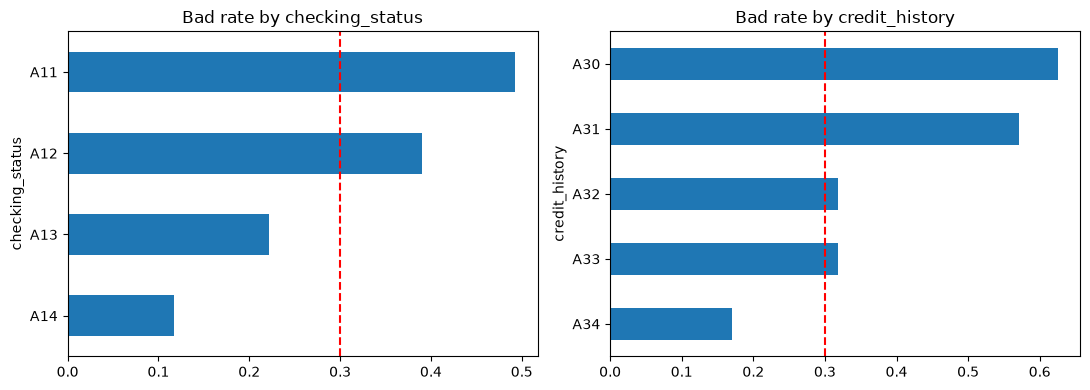

In [4]:
# Key chart 1: bad rate by checking account and credit history
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, c in zip(ax, ["checking_status", "credit_history"]):
    df.groupby(c)["target"].mean().sort_values().plot.barh(ax=a)
    a.axvline(df["target"].mean(), color="red", ls="--"); a.set_title("Bad rate by " + c)
plt.tight_layout(); plt.show()

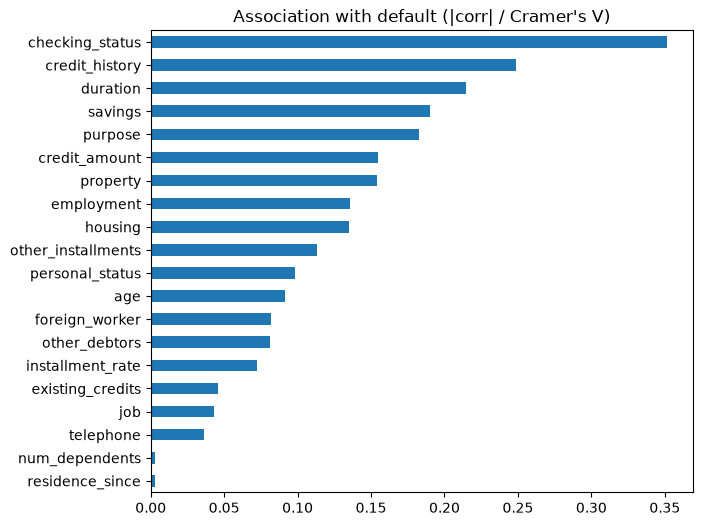

purpose            0.182637
savings            0.189997
duration           0.214927
credit_history     0.248378
checking_status    0.351740
dtype: float64


In [5]:
# Key chart 2: association of every raw feature with target
# numeric -> correlation; categorical -> Cramer's V
def cramers_v(x, y):
    t = pd.crosstab(x, y); n = t.values.sum()
    e = np.outer(t.sum(1), t.sum(0)) / n
    chi2 = ((t - e) ** 2 / e).values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))
assoc = {c: abs(df[c].corr(df["target"])) for c in num_cols}
assoc.update({c: cramers_v(df[c], df["target"]) for c in cat_cols})
assoc = pd.Series(assoc).sort_values()
assoc.plot.barh(figsize=(7, 6), title="Association with default (|corr| / Cramer's V)"); plt.show()
print(assoc.tail(5))

**Finding:** `checking_status` is clearly the strongest, then `credit_history`, `duration`, `savings` and `purpose`.

## 2. Feature engineering & preprocessing
Split comes FIRST. The new features below use only the row itself (no statistics from other rows), so they can't leak. Scaler/encoder are fitted on train only (inside a Pipeline).

In [6]:
X, y = df.drop(columns="target"), df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)

def add_features(d):
    d = d.copy()
    d["monthly_payment"] = d["credit_amount"] / d["duration"]               # how much per month
    d["burden"] = d["monthly_payment"] * d["installment_rate"]              # payment x share of income taken
    return d
X_train, X_test = add_features(X_train), add_features(X_test)
num_cols2 = num_cols + ["monthly_payment", "burden"]

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols2),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
print(X_train.shape, X_test.shape, " bad rate train/test: %.2f / %.2f" % (y_train.mean(), y_test.mean()))

(800, 22) (200, 22)  bad rate train/test: 0.30 / 0.30


**Missing values / encoding:** no missing values, so nothing was imputed. Categorical variables are one-hot encoded (they are nominal, codes like A11/A12 have no numeric meaning); numeric ones are standardized.

**New features**
- `monthly_payment = credit_amount / duration`: a big loan over a long time is lighter than the same loan over a short time.
- `burden = monthly_payment * installment_rate`: monthly payment weighted by the share of income already committed. Higher burden = less room to absorb a shock = higher risk.

**3 most discriminative features (from EDA + SHAP below):** `checking_status` (no/low balance on the current account is the strongest warning sign), `duration` (longer loans are exposed to more uncertainty), `credit_history` (past delays/critical account predict future behaviour).

## 3. Modeling

In [ ]:
def make(model):
    return Pipeline([("prep", prep), ("model", model)])

base = make(DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RS)).fit(X_train, y_train)

grid = {"model__n_estimators": [200, 400], "model__max_depth": [4, 6, None], "model__min_samples_leaf": [1, 5, 10]}
gs = GridSearchCV(make(RandomForestClassifier(random_state=RS)), grid,
                  scoring="roc_auc", cv=5, n_jobs=-1).fit(X_train, y_train)
rf = gs.best_estimator_
print("best RF params:", gs.best_params_, " CV AUC: %.3f" % gs.best_score_)

rows = []
for name, m in [("Decision Tree (baseline)", base), ("Random Forest (tuned)", rf)]:
    p = m.predict_proba(X_test)[:, 1]
    rows.append([name, roc_auc_score(y_test, p), average_precision_score(y_test, p)])
res = pd.DataFrame(rows, columns=["model", "ROC-AUC", "PR-AUC"]).round(3)
print("PR-AUC of a random model = bad rate = %.2f" % y_test.mean())
res

best RF params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}  CV AUC: 0.796
PR-AUC of a random model = bad rate = 0.30


,model,ROC-AUC,PR-AUC
0,Decision Tree (baseline),0.706,0.448
1,Random Forest (tuned),0.793,0.655


The Random Forest uses no class weights on purpose: that keeps its probabilities close to the real default rate, which the cost-based cut-off below needs. PR-AUC is reported because the bad class is the minority; a random model scores ~0.30 on it.

**Cut-off.** The German Credit data comes with a cost matrix: approving a bad customer (FN) costs **5**, rejecting a good one (FP) costs **1**. Minimising expected cost gives: reject if P(bad) > 1/(1+5) = 0.167. We fix this threshold from theory (not tuned on the test set).

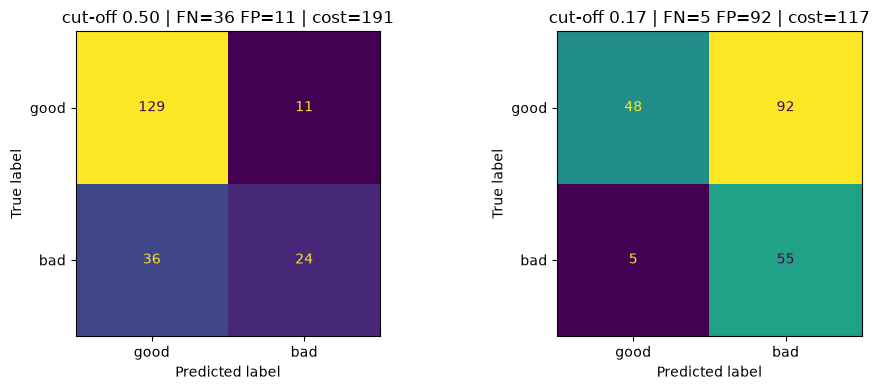

In [8]:
p_rf = rf.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, t in zip(ax, [0.5, 1 / 6]):
    cm = confusion_matrix(y_test, p_rf > t)
    ConfusionMatrixDisplay(cm, display_labels=["good", "bad"]).plot(ax=a, colorbar=False)
    tn, fp, fn, tp = cm.ravel()
    a.set_title("cut-off %.2f | FN=%d FP=%d | cost=%d" % (t, fn, fp, 5 * fn + fp))
plt.tight_layout(); plt.show()

At 0.5 we miss 36 of 60 bad customers (FN, expensive): total cost 191. At 0.167 we miss only 5, but reject 92 of 140 good customers (FP, cheap): total cost 117. With a 5:1 cost ratio the lower cut-off is cheaper, but it is very strict: the bank gives up a lot of good business to avoid defaults. Business can move the cut-off up if growth matters more than risk.

## 4. Explainability (SHAP)

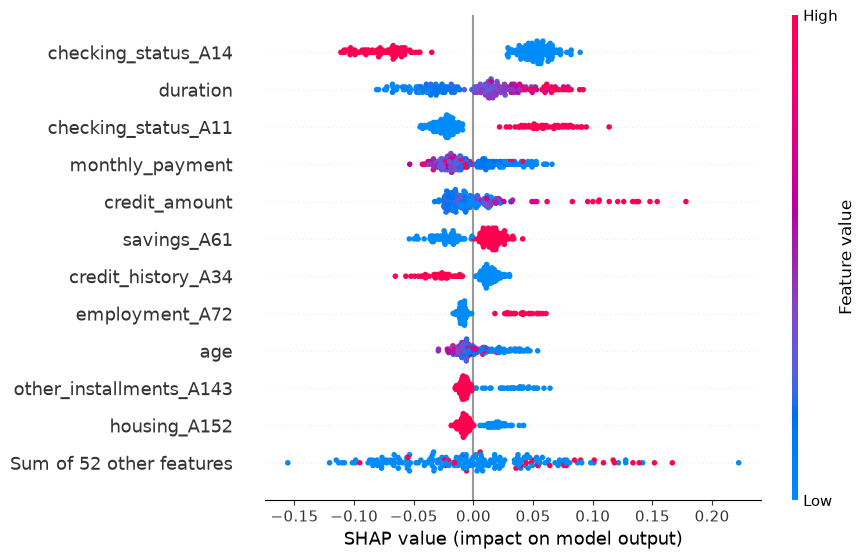

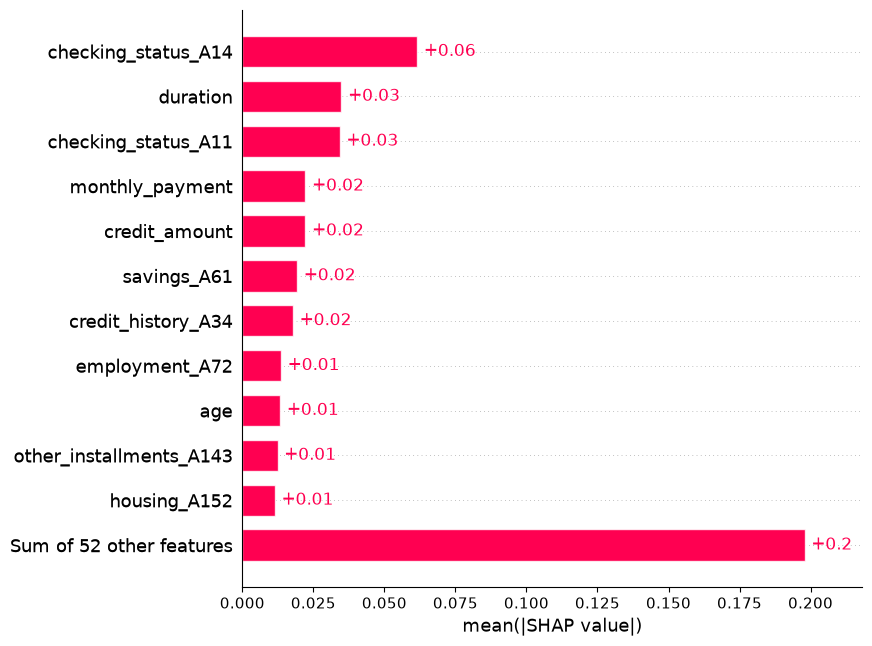

In [9]:
Xt = pd.DataFrame(rf.named_steps["prep"].transform(X_test),
                  columns=rf.named_steps["prep"].get_feature_names_out()).rename(columns=lambda c: c.split("__", 1)[1])
explainer = shap.TreeExplainer(rf.named_steps["model"])
sv = explainer(Xt)[:, :, 1]          # class 1 = bad -> positive SHAP = more risk
shap.plots.beeswarm(sv, max_display=12)
shap.plots.bar(sv, max_display=12)

Beeswarm: red = high feature value. Positive SHAP pushes toward *bad*. Having no checking account (`checking_status_A14`) is the strongest driver and *lowers* risk; a low balance (`A11`), long `duration`, large `credit_amount` and low savings (`A61`) raise it (see causality note).

LOW risk P(bad) = 0.02


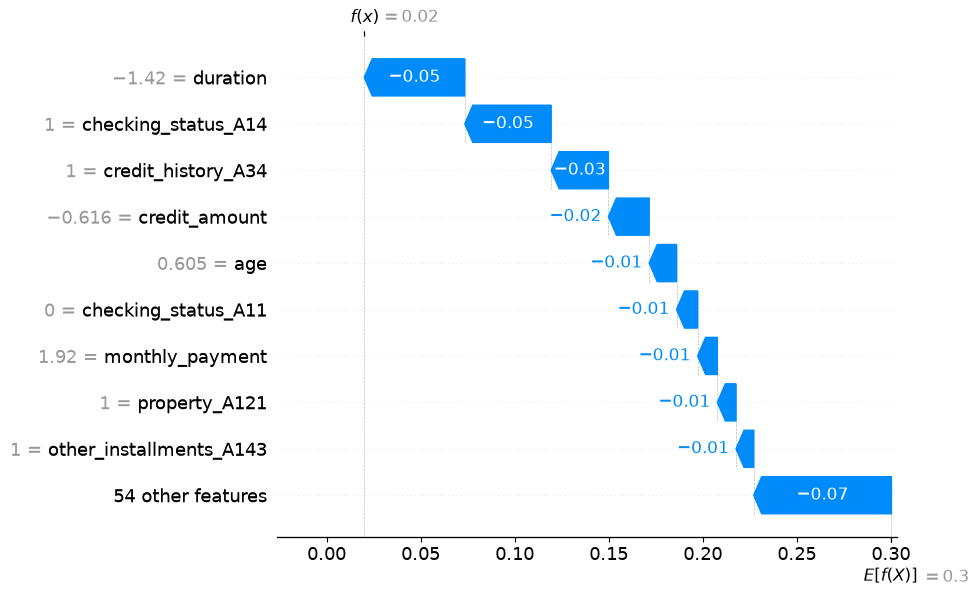

HIGH risk P(bad) = 0.76


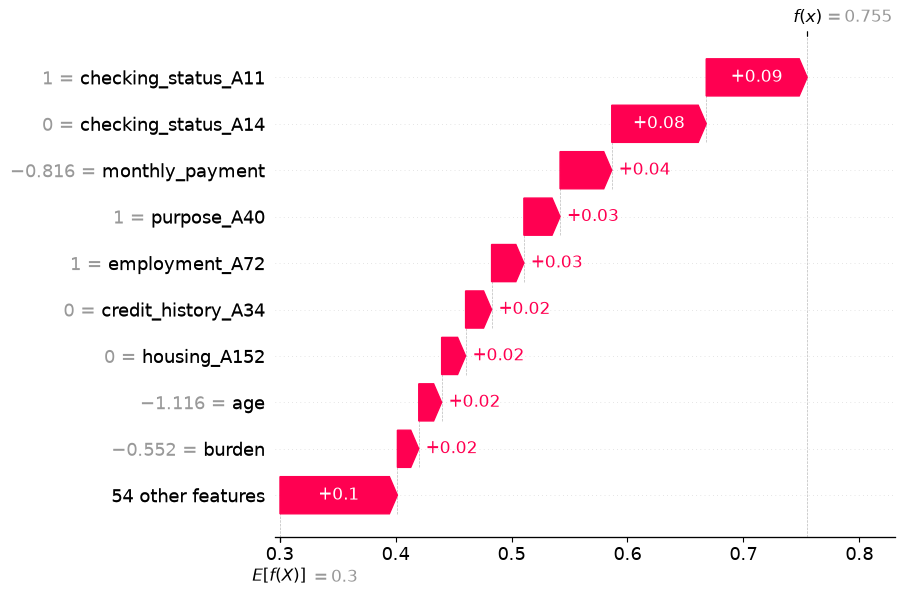

In [10]:
# local explanation: lowest-risk and highest-risk test customers
order = np.argsort(p_rf)
for label, i in [("LOW risk", order[0]), ("HIGH risk", order[-1])]:
    print(label, "P(bad) = %.2f" % p_rf[i])
    shap.plots.waterfall(sv[i], max_display=10)

## 5. Causality vs. correlation
**Cause or just a sign?** SHAP only shows what the model *uses*, not what *causes* default. `duration` and `credit_amount` plausibly have a direct effect (longer, bigger loans = more exposure and more time for things to go wrong), and `burden` is close to mechanical (less income left over). `checking_status`, `savings` and `credit_history` are more like *signs* of an underlying financial situation. Surprisingly, 'no checking account' looks safe: probably those are customers with a different relationship with the bank, not an effect of having no account. Age and education-type variables can be correlated with default only through hidden factors (**confounders**) like job stability and income, which also drive education and default; the model never sees income directly.

**Policy.** A manager can act on things the bank controls: loan duration, amount, installment rate, or requiring a guarantor. Setting a policy on a pure correlate (e.g. "give everyone a checking account" or "lend more to older people") won't change the real risk, because we would change the sign, not the cause. It could also be risky and unfair: the bank would lose money while the underlying behaviour stays the same. Causal claims would need an experiment (A/B test on loan terms) or causal methods, not just this model.

## Optional: LIME vs SHAP (same high-risk customer)
LIME fits a small linear model around ONE customer by perturbing it. If it agrees with SHAP, we trust the explanation more.

In [11]:
from lime.lime_tabular import LimeTabularExplainer
Xtr = pd.DataFrame(rf.named_steps["prep"].transform(X_train), columns=Xt.columns)
lime_exp = LimeTabularExplainer(Xtr.values, feature_names=list(Xt.columns), class_names=["good", "bad"],
                                mode="classification", random_state=RS)
i = order[-1]                                   # same high-risk customer as the waterfall above
le = lime_exp.explain_instance(Xt.values[i], rf.named_steps["model"].predict_proba, num_features=8)
shap_top = pd.Series(sv[i].values, index=Xt.columns).abs().nlargest(8).index.tolist()
lime_top = [r for r, w in sorted(le.as_list(), key=lambda t: -abs(t[1]))]
pd.DataFrame({"SHAP top 8": shap_top, "LIME top 8 (rule)": lime_top})

,SHAP top 8,LIME top 8 (rule)
0,checking_status_A11,checking_status_A14 <= 0.00
1,checking_status_A14,0.00 < checking_status_A11 <= 1.00
2,monthly_payment,credit_history_A31 <= 0.00
3,purpose_A40,credit_history_A30 <= 0.00
4,employment_A72,monthly_payment <= -0.65
5,credit_history_A34,employment_A72 > 0.00
6,housing_A152,property_A124 <= 0.00
7,age,other_installments_A141 <= 0.00


LIME gives a rule-like list (e.g. `checking_status_A11 > 0.00`), SHAP gives exact additive values. Compare the two columns: the checking-account features should be near the top in both. They can differ on weaker features because LIME is a random local approximation, so SHAP stays our main tool.

## Optional: LLM explanation for the rejected customer
The prompt is built from the REAL SHAP values of the high-risk customer above.

In [12]:
# only factors that are clear and TRUE for this customer: one-hot value must be 1 (not 0), vague features left out
nice = {"checking_status_A11": "checking account balance is below zero", "checking_status_A12": "low checking account balance",
        "duration": "long loan duration", "credit_amount": "large loan amount", "savings_A61": "savings under 100 DM",
        "employment_A72": "current job for less than 1 year", "purpose_A40": "loan purpose is a new car"}
s_i = pd.Series(sv[i].values, index=Xt.columns).sort_values(ascending=False)
top = s_i[[f for f in s_i.index if f in nice and Xt.loc[i, f] != 0 and s_i[f] > 0]].head(4)
shap_list = "\n".join("- " + nice.get(f, f) for f in top.index)
prompt = (
    "You are a polite bank assistant. A loan application was rejected. The main factors behind the decision:\n"
    + shap_list + "\n"
    "1. In simple, non-technical, respectful language, explain to the customer why the application was declined.\n"
    "2. Give 2-3 concrete steps to improve their credit profile in the coming months.\n"
    "Do not mention SHAP, models or probabilities.")
print(prompt)

You are a polite bank assistant. A loan application was rejected. The main factors behind the decision:
- checking account balance is below zero
- loan purpose is a new car
- current job for less than 1 year
- savings under 100 DM
1. In simple, non-technical, respectful language, explain to the customer why the application was declined.
2. Give 2-3 concrete steps to improve their credit profile in the coming months.
Do not mention SHAP, models or probabilities.


**Sample LLM answer** (generated from the prompt above; to reproduce, paste the printed prompt into LLM):

> Dear customer, thank you for applying. After careful review we are unable to approve this loan right now. The main reasons are: your checking account balance has recently been below zero, you have been in your current job for less than a year, your savings are still small, and this loan is for a new car, which is a larger purchase. Together these make us less sure that the repayments would be comfortable for you at this time.
>
> This is not a permanent decision. Here is what can help:
> 1. **Keep your checking account in the positive.** A few months of steady, positive balances shows us you manage your money well.
> 2. **Build a small savings cushion.** Even a small monthly transfer to a savings account helps a lot over time.
> 3. **Apply again after about a year in your job**, or consider a smaller or used-car loan, which is easier to approve.
>
> We would be glad to review your application again.